In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# Some global variables
# root
ROOT = Path.cwd()
DATA = ROOT / "data"
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED)
print(f"tensorflow: {tf.__version__}\ndataset found: {DATA.is_dir()}\nFolder path: {DATA}")

I0000 00:00:1794654206.473653   80555 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


tensorflow: 2.23.0-dev20261112
dataset found: True
Folder path: /home/ishan/projects/DL/potato_leaf/data


# check the class folders (x and y) in the dataset directory

In [3]:
classes = sorted(p.name for p in DATA.iterdir() if p.is_dir()) if DATA.exists() else []
counts = {name: len([p for p in (DATA/name).iterdir() if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]) for name in classes}
print("image per class:", counts)

#optional:
assert len(classes) == 3 and all(v > 0 for v in counts.values()), "Dataset should have 3 classes with at least one image in each."

image per class: {'Potato___Early_blight': 1000, 'Potato___Late_blight': 1000, 'Potato___healthy': 152}


# display three real images: open actual file per class, convert it into RGB and display it.

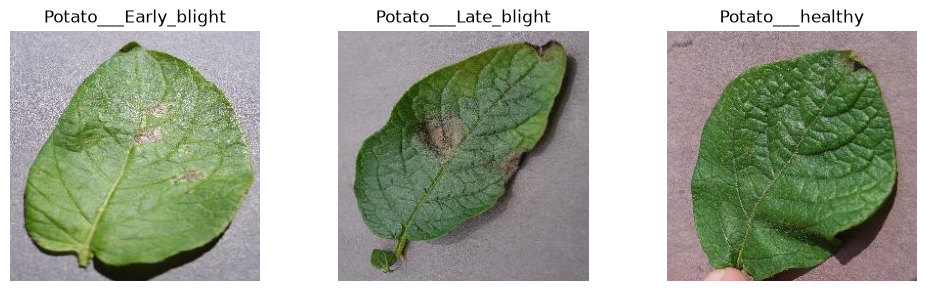

In [4]:
fig, axes = plt.subplots(1, 3, figsize = (10, 3))
for i, name in zip(axes, classes):
    folder = DATA/name
    file = next(p for p in folder.iterdir() if p.suffix.lower() in ['.jpg', '.jpeg', '.png'])
    with Image.open(file) as img:
        img = img.convert("RGB")
        i.imshow(img)
        i.set_title(name)
        i.axis("off")

plt.tight_layout()
plt.show()

# Split data in training and validation

In [5]:
train_ds = tf.keras.utils.image_dataset_from_directory(DATA, validation_split=0.2, subset="training", seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE, color_mode="rgb", label_mode="int")
validation_ds = tf.keras.utils.image_dataset_from_directory(DATA, validation_split=0.2, subset="validation", seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE, color_mode="rgb", label_mode="int")

class_names = train_ds.class_names

images, labels = next(iter(train_ds))

print(f"class order: {class_names}\nimage in one batch: {images.shape}\nlabels in one batch: {labels[:8].numpy()}")

Found 2152 files belonging to 3 classes.
Using 1722 files for training.


I0000 00:00:1794654232.444039   80555 service.cc:155] XLA service 0x3df6a850 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794654232.445224   80555 service.cc:171]   StreamExecutor [0]: NVIDIA GeForce GTX 1650, Compute Capability 7.5 (Driver: 13.5.0[621.1.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794654232.456008   80555 gpu_device.cc:1908] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2244 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE


Found 2152 files belonging to 3 classes.


libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE


Using 430 files for validation.
class order: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
image in one batch: (32, 128, 128, 3)
labels in one batch: [0 1 2 1 0 0 0 0]


# Data augmentation: rotation, zoom, horizontal, vertical.


libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE


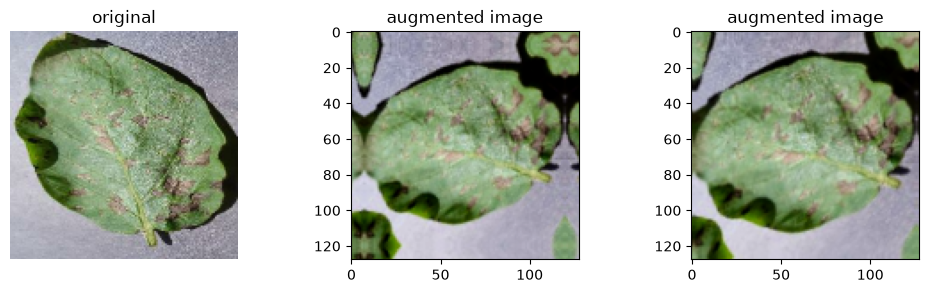

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [6]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(height_factor=(-0.2, 0.2)),
    tf.keras.layers.RandomContrast(0.2)
])

sample = images[0:1]
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
axes[0].imshow(tf.cast(sample[0], tf.uint8))
axes[0].set_title("original")

for i in (1, 2):
    augmented = augmentation(sample, training=True)[0]
    axes[i].imshow(tf.cast(tf.clip_by_value(augmented, 0, 255), tf.uint8))
    axes[i].set_title("augmented image")

for i in axes:
    i.axis("off")
    plt.tight_layout()
    plt.show()

# Creating the model with all the layers

In [7]:
model = tf.keras.Sequential([
    # Input with height=128, weight=128, color=rgb/3channels
    tf.keras.Input(shape=(128,128,3)),

    # Rescaling the value and preforming augmentation
    tf.keras.layers.Rescaling(1.0/255),
    augmentation,

    # Feature extraction
    tf.keras.layers.Conv2D(32, 3, padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(256, 3, padding='same', use_bias=False),
    tf.keras.layers.BatchNormalization(momentum=0.9),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(),

    # Flattening
    # tf.keras.layers.Flatten(),
    tf.keras.layers.GlobalAveragePooling2D(),

    # Classifier
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(3, activation='softmax')
])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 423,139 (1.61 MB)

 Trainable params: 422,179 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [8]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("\nAvailable GPUs:")

gpus = tf.config.list_physical_devices('GPU')

for gpu in gpus:
    print(gpu)

if not gpus:
    print("No GPU detected. Training may be running on CPU.")

TensorFlow version: 2.23.0-dev20261112

Available GPUs:
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


# Adam optimizer and training

In [9]:

train_labels = np.concatenate([y.numpy() for _, y in train_ds])

class_counts = np.bincount(train_labels, minlength=len(class_names))
class_weights = {i: len(train_labels)/(len(class_names)*count) for i, count in enumerate(class_counts)}
class_weights = {i: float(np.sqrt(w)) for i, w in class_weights.items()}
print(f"training class counts: {dict(zip(class_names, class_counts))}\n class weights: {class_weights}")

model.compile(optimizer=Adam(learning_rate=0.00001), loss="sparse_categorical_crossentropy", metrics=['accuracy'])

#apply callback (model_check_point)
callbacks_list = [
    EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]
history = model.fit(train_ds, validation_data=validation_ds, epochs=50, class_weight=class_weights, callbacks=callbacks_list)

training class counts: {'Potato___Early_blight': np.int64(818), 'Potato___Late_blight': np.int64(792), 'Potato___healthy': np.int64(112)}
 class weights: {0: 0.8376822138750128, 1: 0.8513210174472816, 2: 2.2638462845343543}
Epoch 1/50


/home/ishan/projects/DL/potato_leaf/venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
I0000 00:00:1794654261.895870   80776 cuda_dnn.cc:505] Loaded cuDNN version 92801
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE
libunwind: __unw_add_dynamic_fde: bad fde: FDE is really a CIE


 2/54 ━━━━━━━━━━━━━━━━━━━━ 8s 168ms/step - accuracy: 0.2031 - loss: 1.3762 

W0000 00:00:1794654268.949705   80555 prefetch_dataset_op.cc:478] SEVERE STARVATION: Element UID 1794654254799358336 in buffer 'PrefetchDataset/_20' sat unconsumed for 14.1501 seconds!


54/54 ━━━━━━━━━━━━━━━━━━━━ 28s 263ms/step - accuracy: 0.5842 - loss: 0.8505 - val_accuracy: 0.8651 - val_loss: 0.6147 - learning_rate: 1.0000e-05
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 145ms/step - accuracy: 0.8118 - loss: 0.5780 - val_accuracy: 0.7372 - val_loss: 0.5965 - learning_rate: 1.0000e-05
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 144ms/step - accuracy: 0.8502 - loss: 0.4565 - val_accuracy: 0.7791 - val_loss: 0.5216 - learning_rate: 1.0000e-05
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 7s 125ms/step - accuracy: 0.8804 - loss: 0.3923 - val_accuracy: 0.8140 - val_loss: 0.4688 - learning_rate: 1.0000e-05
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - accuracy: 0.8769 - loss: 0.3573 - val_accuracy: 0.8233 - val_loss: 0.4426 - learning_rate: 1.0000e-05
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - accuracy: 0.9059 - loss: 0.2971 - val_accuracy: 0.8349 - val_loss: 0.4244 - learning_rate: 1.0000e-05
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - accuracy: 0.9117 - l

# Visualization of loss and acurracy

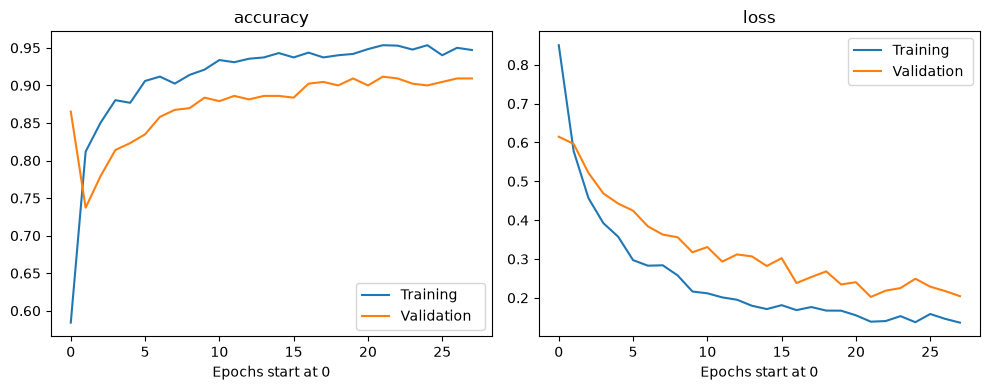

In [10]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Training  ') 
plt.plot(history.history['val_accuracy'], label='Validation  ')
plt.title('accuracy')
plt.xlabel('Epochs start at 0')
plt.legend()


plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Training ')
plt.plot(history.history['val_loss'], label='Validation ')
plt.title('loss')
plt.xlabel('Epochs start at 0')
plt.legend()    

plt.tight_layout()
plt.show()

# Confusion Matrix

validation accuracy:0.91 not test accuracy


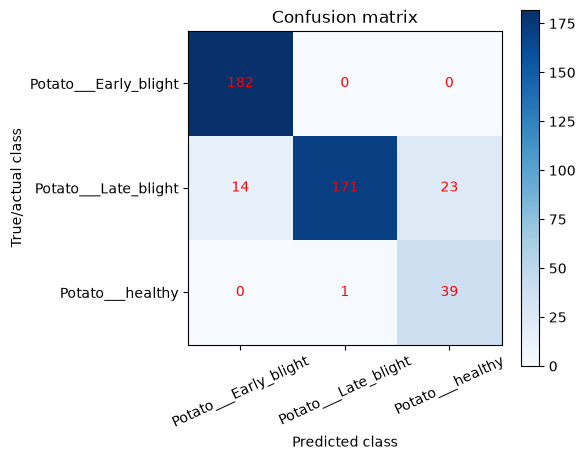

In [11]:
all_true,all_pred=[],[]
for batch_images,batch_labels in validation_ds:
    scores=model.predict(batch_images,verbose=0)
    all_true.extend(batch_labels.numpy())
    all_pred.extend(np.argmax(scores,axis=1))

matrix=tf.math.confusion_matrix(all_true,all_pred,num_classes=len(class_names)).numpy()

accuracy=np.mean(np.array(all_true)==np.array(all_pred))
print(f"validation accuracy:{accuracy:.2f} not test accuracy")

plt.figure(figsize=(6,5))
plt.imshow(matrix, cmap="Blues")
plt.colorbar()

plt.xticks(range(3),[s.replace("potato__","") for s in class_names],rotation=25)
plt.yticks(range(3),[s.replace("potato__","") for s in class_names]) 
plt.xlabel("Predicted class")
plt.ylabel("True/actual class")
plt.title("Confusion matrix")  


for i in range(3):
    for j in range(3):
        plt.text(j,i, matrix[i,j], ha="center", va="center", color="red")
plt.tight_layout()
plt.show()

# Save the model

In [12]:
model.save("potato_cnn_model.keras")
Path("classification_report.txt").write_text("\n".join(class_names),encoding="utf-8")
print("model saved to potato_cnn_model.keras and class names saved to classification_report.txt")

model saved to potato_cnn_model.keras and class names saved to classification_report.txt


# Prediction on unseen data

model score 0.96
Potato___Early_blight : 0.02
Potato___Late_blight : 0.01
Potato___healthy : 0.96


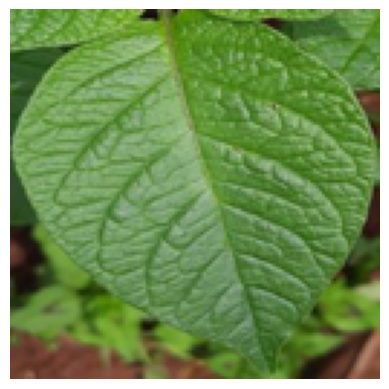

In [19]:
image_path = ROOT / "image.png"
if image_path.is_file():
    with Image.open(image_path) as file:
        image = file.convert("RGB").resize(IMG_SIZE)
    x=np.expand_dims(np.array(image,dtype=np.float32),axis=0)
    scores=model.predict(x,verbose=0)[0]
    best= int(np.argmax(scores))
    print("model score",f"{scores[best]:.2f}")
    for name, score in zip(class_names,scores):
        print(f"{name.replace('potato__','')} : {score:.2f}")
    plt.imshow(image)
    plt.axis("off")
    plt.show()
else:
    print(" place an image named leaf.jpg beside this notebook and run cell again")
    